# OISST: marine heatwaves in the Gulf of Maine

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ocean-icechunks/2026-ioos-hackathon/blob/main/examples/05-oisst-gulf-of-maine-heatwaves.ipynb)

The Gulf of Maine is one of the fastest-warming patches of ocean on Earth, and its 2012 marine
heatwave upended the lobster season ([Mills et al. 2013](https://doi.org/10.5670/oceanog.2013.27)).
Here we count marine heatwave days in every year since 1982, from NOAA's daily
[OISST v2.1](https://www.ncei.noaa.gov/products/optimum-interpolation-sst).

That takes the full daily record, **about 16,500 NetCDF files**. The
[virtual Icechunk store](https://source.coop/ocean-icechunks/noaa-oisst), maintained by
NERACOOS / GMRI, makes them one dataset, so it is one `sel()`. No credentials needed.

## What counts as a marine heatwave

The standard definition ([Hobday et al. 2016](https://doi.org/10.1016/j.pocean.2015.12.014)):
a marine heatwave is **at least 5 days in a row** when the temperature is above the
**90th percentile for that day of the year**, measured against a 30-year baseline. Here the
baseline is 1991–2020, and the percentile is smoothed with a 31-day running mean (a slight
simplification of Hobday's method).

In [ ]:
%pip install -q "icechunk>=2.3" "xarray>=2026.7" "zarr>=3.4" matplotlib

## Open the dataset

The `daily/` group holds only references; every value is read by byte range from NOAA's files on
AWS.

In [2]:
import time
import icechunk, xarray as xr, zarr
import matplotlib.pyplot as plt

zarr.config.set({"async.concurrency": 32})

url = "https://data.source.coop/ocean-icechunks/noaa-oisst/oisst.icechunk"
repo = icechunk.Repository.open(icechunk.http_storage(url))
# The data stay in NOAA's public S3 bucket: allow anonymous reads there.
auth = icechunk.containers_credentials(
    {p: icechunk.s3_anonymous_credentials() for p in repo.config.virtual_chunk_containers})
repo = repo.reopen(authorize_virtual_chunk_access=auth)
daily = xr.open_zarr(repo.readonly_session("main").store, group="daily",
                     consolidated=False, chunks=None)
daily

<xarray.Dataset> Size: 548GB
Dimensions:      (time: 16508, zlev: 1, lat: 720, lon: 1440)
Coordinates:
  * time         (time) datetime64[ns] 132kB 1981-09-01T12:00:00 ... 2026-11-...
    preliminary  (time) bool 17kB ...
  * zlev         (zlev) float32 4B 0.0
  * lat          (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon          (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    anom         (time, zlev, lat, lon) float64 137GB ...
    err          (time, zlev, lat, lon) float64 137GB ...
    ice          (time, zlev, lat, lon) float64 137GB ...
    sst          (time, zlev, lat, lon) float64 137GB ...
Attributes: (12/38)
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...
    source:                     ICOADS, NCEP_GTS, GSFC_ICE, NCEP_ICE, Pathfin...
    id:                         oisst-avhrr-v02r01.20261111_preliminary.nc
    naming_authority:           gov.noaa.ncei
    summary:                    NOAAs 1/4-degree Daily Optimum Interpolation ...
    cdm_data_type:              Grid
    ...                         ...
    ncei_template_version:      NCEI_NetCDF_Grid_Template_v2.0
    comment:                    Data was converted from NetCDF-3 to NetCDF-4 ...
    sensor:                     Thermometer, AVHRR
    Conventions:                CF-1.6, ACDD-1.3
    references:                 Reynolds, et al.(2007) Daily High-Resolution-...
    Description:                Reynolds, et al.(2007) Daily High-resolution ...

## Every day since 1981, averaged over the Gulf of Maine

A box from 42 to 44.5 °N and 70.5 to 66 °W; land reads as `NaN` and drops out of the mean. Each
chunk in NOAA's files is a whole global map, so even this small box reads every file once. It
took about 3 minutes on a JupyterHub in AWS; elsewhere, including Colab, expect longer.

With 16,500 requests, a dropped connection now and then is likely, and one is enough to stop a
single big read. So read a year at a time, and try a year again if it fails.

In [3]:
box = daily.sst.squeeze("zlev").sel(lat=slice(42, 44.5), lon=slice(289.5, 294))

def read_year(year, tries=3):
    for attempt in range(tries):
        try:
            return box.sel(time=str(year)).mean(["lat", "lon"]).load()
        except Exception as err:          # usually a dropped connection: try again
            print(f"{year}: attempt {attempt + 1} failed ({type(err).__name__})")
    raise RuntimeError(f"could not read {year}")

start = time.time()
gom = xr.concat([read_year(y) for y in range(1981, daily.time.dt.year.values[-1] + 1)], dim="time")
print(f"{gom.time.size:,} days read in {time.time() - start:.0f} s")

16,508 days read in 139 s


## Find the heatwave days

In [4]:
base = gom.sel(time=slice("1991", "2020")).groupby("time.dayofyear")

def smooth(c):   # 31-day running mean, wrapping around the new year
    return c.pad(dayofyear=15, mode="wrap").rolling(dayofyear=31, center=True).mean()[15:-15]

clim = smooth(base.mean())
p90 = smooth(base.quantile(0.9)).drop_vars("quantile")

doy = gom.time.dt.dayofyear
hot = (gom > p90.sel(dayofyear=doy)).to_series()
run = hot.ne(hot.shift()).cumsum()                         # number each run of hot / not-hot days
heatwave = hot & hot.groupby(run).transform("size").ge(5)  # keep runs of 5 days or more
days_per_year = heatwave.groupby(heatwave.index.year).sum().loc[1982:]

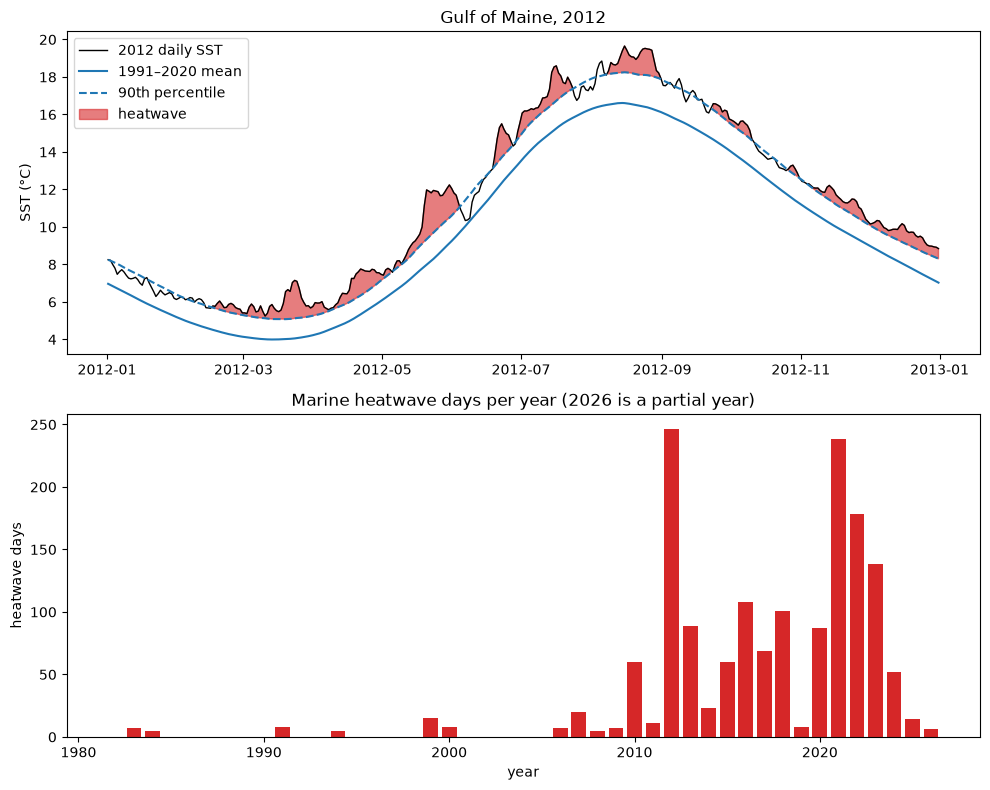

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

y = "2012"
one = gom.sel(time=y)
ax1.plot(one.time, one, color="k", lw=1, label=f"{y} daily SST")
ax1.plot(one.time, clim.sel(dayofyear=one.time.dt.dayofyear), color="tab:blue", label="1991–2020 mean")
ax1.plot(one.time, p90.sel(dayofyear=one.time.dt.dayofyear), color="tab:blue", ls="--", label="90th percentile")
ax1.fill_between(one.time, p90.sel(dayofyear=one.time.dt.dayofyear), one,
                 where=heatwave.loc[y].values, color="tab:red", alpha=0.6, label="heatwave")
ax1.set(ylabel="SST (°C)", title=f"Gulf of Maine, {y}")
ax1.legend(loc="upper left")

ax2.bar(days_per_year.index, days_per_year, color="tab:red")
ax2.set(xlabel="year", ylabel="heatwave days",
        title=f"Marine heatwave days per year ({days_per_year.index[-1]} is a partial year)")
plt.tight_layout()
plt.show()

In 2012 (top) the Gulf of Maine sat above its 90th percentile for most of the year: 246
heatwave days. Before 2010, heatwaves here were rare, about 3 days a year on average and never
more than 20. Since 2010 the average is 93 days a year, with 2021 (238 days) close to 2012.
2024–2026 have been calmer so far.

One caution: the baseline is fixed at 1991–2020, so a steadily warming ocean shows up as more
heatwave days. Hobday et al. discuss this; detrending first, or a moving baseline, separates
short extremes from the long-term warming.

**More:** NOAA's [OISST page](https://www.ncei.noaa.gov/products/optimum-interpolation-sst) and
the [store's README](https://github.com/ocean-icechunks/noaa_oisst), which also describes the
`monthly/` group for long, cheap time series.